# 3. AGN tori, ionisation cones and jets

`System3D` composes scenes from named parts: **lamps** (point X-ray sources that also light everything
else), opaque **bodies** (here a `Torus`) and optically thin **volumes** (here `BiCone`, `Shell`,
`GasTorus`, `Jet`). This notebook builds

1. a Seyfert nucleus: corona, an opaque torus that Compton-reflects from its inner face, a clumpy
   broad-line region and ionisation cones that electron-scatter the nucleus;
2. a torus of *gas* instead, to follow the nucleus's transmitted spectrum with inclination, smooth and
   clumpy;
3. a relativistic two-sided jet with knots, and its Doppler-boosted jet / counter-jet asymmetry.

All parameters are round numbers for illustration, not fits to particular sources.

In [2]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import xrimodel as xm
from xrimodel.engine import BiCone, GasTorus, Jet, Lamp, Scene, Shell, System3D, Torus
from xrimodel.units import UAS_PER_RAD

warnings.filterwarnings("ignore", message=".*electron-scattering optical depth.*")
corona = {"kind": "powerlaw", "gamma": 1.8, "norm": 0.02}
cmap = plt.get_cmap("magma").copy()
cmap.set_bad(cmap(0.0))   # black: no emission


def band_image(model, grid, lo, hi):
    tot = np.zeros(grid.n)
    for L in model.layers:
        if L.grid.n > 1:
            tot += xm.specmap_projection(L, edges=np.linspace(lo, hi, 41))[1]
    return grid.to_image(tot) / (grid.scale / UAS_PER_RAD) ** 2   # photons/s/cm2/sr


def extent(grid, unit=1.0):
    h = grid.nx / 2 * grid.scale / unit
    return [h, -h, -h, h]

## 1. A Seyfert nucleus

At 15 Mpc, 1 pc is 13.8 mas. The torus (major radius 0.6 pc, tube radius 0.3 pc) blocks lines of sight more than 60° from its axis; at 50° we look over its near rim at the far side's inner face, the only part the corona illuminates. The dashed line is the torus's whole silhouette.

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


agn_blr0     1.02e-05 photons/s/cm^2
agn_blr1     1.66e-04 photons/s/cm^2
agn_blr2     2.99e-03 photons/s/cm^2
agn_blr3     9.04e-04 photons/s/cm^2
agn_cones0   1.07e-05 photons/s/cm^2
agn_cones1   2.05e-06 photons/s/cm^2
agn_cones2   1.91e-05 photons/s/cm^2
agn_cones3   7.36e-07 photons/s/cm^2
agn_torus    3.63e-03 photons/s/cm^2
agn_corona   6.21e-02 photons/s/cm^2


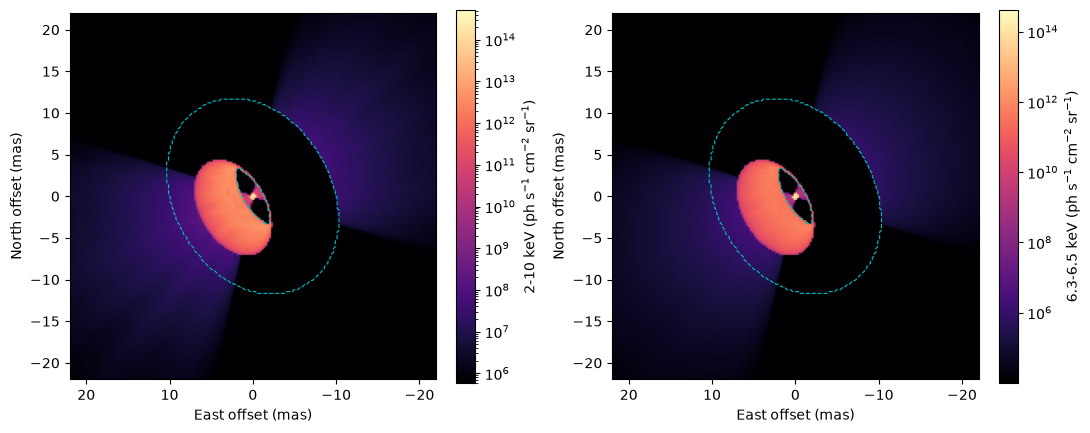

In [3]:
def seyfert(inclination, torus):
    return System3D(
        name="agn", length_unit="pc", inclination=inclination, node_pa=30.0, nh_ism=2e20,
        lamps=[Lamp(name="corona", spectrum=corona)], bodies=[torus], extent=3.2,
        volumes=[Shell(name="blr", r_in=0.005, r_out=0.03, n0=2e6, index=1.0, absorption="xi",
                       clumping={"f_vol": 0.05, "size": 0.15, "seed": 1},
                       lines=[{"e0": 6.4, "sigma": 0.03, "yield": 0.5}]),
                 BiCone(name="cones", r_in=0.05, r_out=3.0, half_angle=35.0, n0=3e4, index=2.0,
                        v_r=500.0, absorption="none")])


grid = xm.RegularGrid(nx=200, ny=200, scale=220.0)          # 0.22 mas pixels
scene = Scene(ra=182.6357, dec=39.4057, distance_pc=15.0e6, grid=grid)
scene.add(seyfert(50.0, Torus(name="torus", r_major=0.6, r_minor=0.3, albedo=0.1, mass_msun=4e7)))
agn = scene.render()
for L in agn.layers:
    print(f"{L.name:12s} {L.mean_photon_flux():.2e} photons/s/cm^2")

outline = Scene(ra=scene.ra, dec=scene.dec, distance_pc=scene.distance_pc, grid=grid)
outline.add(System3D(name="o", length_unit="pc", inclination=50.0, node_pa=30.0, supersample=1,
                     extent=3.2, bodies=[Torus(name="torus", r_major=0.6, r_minor=0.3,
                                               reflection=None,
                                               emission={"spectrum": corona, "intensity": 1.0})]))
silhouette = grid.to_image(outline.render().layer("o_torus_emit").maps["NORM"] > 0)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, (lo, hi), lab in [(ax[0], (2.0, 10.0), "2-10 keV"), (ax[1], (6.3, 6.5), "6.3-6.5 keV")]:
    img = band_image(agn, grid, lo, hi)
    pos = img[img > 0]
    im = a.imshow(np.where(img > 0, img, np.nan), origin="lower", extent=extent(grid, 1e3),
                  cmap=cmap, norm=LogNorm(vmin=np.percentile(pos, 1), vmax=pos.max()))
    a.contour(silhouette.astype(float), levels=[0.5], extent=extent(grid, 1e3), origin="lower",
              colors="c", linewidths=0.8, linestyles="--")
    a.set_xlabel("East offset (mas)"); a.set_ylabel("North offset (mas)")
    fig.colorbar(im, ax=a, label=f"{lab} (ph s$^{{-1}}$ cm$^{{-2}}$ sr$^{{-1}}$)", fraction=0.046)
fig.tight_layout()

## 2. A torus of gas: transmission with inclination

An opaque body hides the nucleus completely beyond 60°. A `GasTorus` instead absorbs it: the nucleus's layer carries the absorbing column `NH` and the electron column `NE` along the line of sight, and the sampler removes photons by photoabsorption and by Klein-Nishina scattering out of the beam. Here the tube has a Gaussian density profile with 3×10²⁴ cm⁻² through its middle (Compton-thick), smooth and clumpy (10% filling factor, same mean density).

Only the nucleus matters here, so the scene is rendered on a tiny grid.

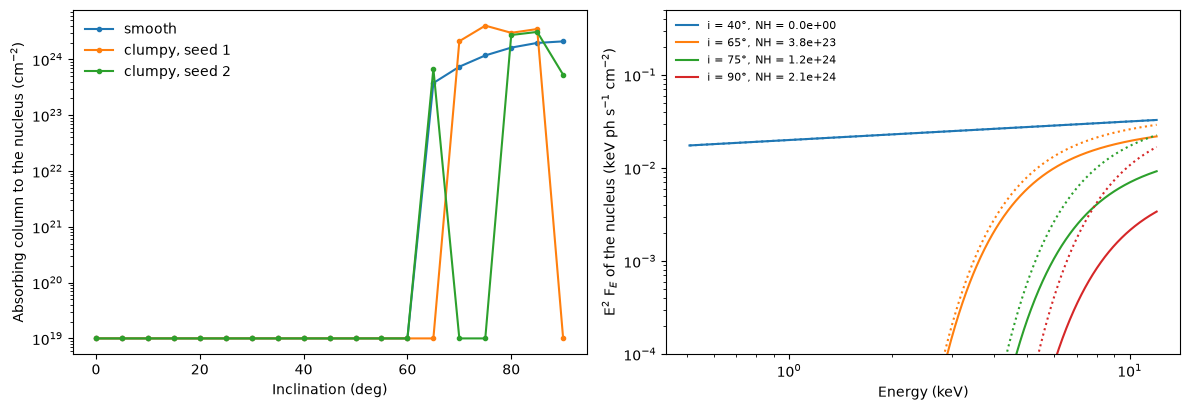

In [4]:
n0 = 3e24 / (0.6 * 3.0857e18 * 0.5 * np.sqrt(2 * np.pi) * 0.6827)   # NH through the tube middle
tiny = xm.RegularGrid(nx=4, ny=4, scale=2e4)
incs = np.arange(0.0, 90.1, 5.0)
cols = {}
for lab, clump in [("smooth", None), ("clumpy, seed 1", {"f_vol": 0.1, "size": 0.15, "seed": 1}),
                   ("clumpy, seed 2", {"f_vol": 0.1, "size": 0.15, "seed": 2})]:
    out = []
    for inc in incs:
        sc = Scene(ra=0.0, dec=0.0, distance_pc=15.0e6, grid=tiny)
        sc.add(System3D(name="t", length_unit="pc", inclination=float(inc),
                        lamps=[Lamp(name="corona", spectrum=corona)],
                        volumes=[GasTorus(name="torus", r_major=0.6, r_minor=0.3, n0=n0,
                                          profile="gaussian", clumping=clump)]))
        lamp = sc.render().layer("t_corona")
        out.append((lamp.maps["NH"][0], lamp.maps["NE"][0]))
    cols[lab] = np.array(out)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for lab, c in cols.items():
    ax[0].semilogy(incs, np.maximum(c[:, 0], 1e19), "o-", ms=3, label=lab)
ax[0].set_xlabel("Inclination (deg)"); ax[0].set_ylabel("Absorbing column to the nucleus (cm$^{-2}$)")
ax[0].legend(frameon=False)

e = xm.energy_grid(0.5, 12.0, 0.02)
ec = 0.5 * (e[1:] + e[:-1])
base = xm.powerlaw(e, 1.8, 0.02).values
for inc in (40.0, 65.0, 75.0, 90.0):
    nh, ne = cols["smooth"][int(inc / 5)]
    sig_abs = xm.format.spectra.sigma_photoabs(ec)
    sig_kn = xm.format.spectra.sigma_kn(ec)
    l, = ax[1].loglog(ec, ec**2 * base * np.exp(-nh * sig_abs - ne * sig_kn),
                      label=f"i = {inc:.0f}°, NH = {nh:.1e}")
    ax[1].loglog(ec, ec**2 * base * np.exp(-nh * sig_abs), ls=":", color=l.get_color())
ax[1].set_ylim(1e-4, 0.5)
ax[1].set_xlabel("Energy (keV)"); ax[1].set_ylabel("E$^2$ F$_E$ of the nucleus (keV ph s$^{-1}$ cm$^{-2}$)")
ax[1].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()

Solid lines include electron scattering out of the beam, dotted lines photoabsorption alone: at
Compton-thick columns the scattering losses dominate above ~10 keV. Clumping makes the column a matter
of chance: some sightlines pass between clumps, others hit several.

The gas torus only scatters once, so its Compton *reflection* (many scatterings in thick gas) is not
modelled; for that, keep the opaque `Torus` body, as in part 1.

## 3. A relativistic jet

A microquasar-like jet (Lorentz factor 2, half-opening 4°) at 60° to the line of sight, 2 kpc away,
with three knots on each side moving with the flow. A steady jet's band photon flux scales as the
Doppler factor squared, a moving knot's as its cube, so the approaching side is brighter by
((1 + β cos i)/(1 − β cos i))² for the jet and the cube of that for the knots.

jet / counter-jet flux ratio 6.8; steady jet alone 6.4, knots alone 16.1
G approaching 0.882, receding 0.349


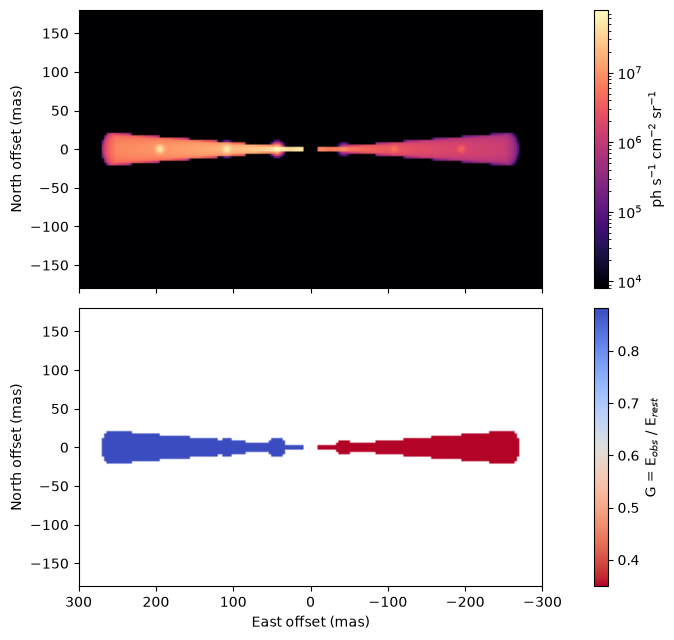

In [5]:
gam, inc = 2.0, 60.0
beta = np.sqrt(1 - 1 / gam**2)
jet = Jet(name="jet", r0=5.0, r1=600.0, half_angle=4.0, index=2.0, lorentz=gam, n0=1.0,
          knots=[{"r": r, "size": 6.0, "j": 3e-7} for r in (100.0, 250.0, 450.0)],
          emission={"spectrum": {"kind": "powerlaw", "gamma": 1.7, "norm": 1.0}, "j0": 1e-4},
          n_fine=4096)
jgrid = xm.RegularGrid(nx=200, ny=120, scale=3000.0)   # 3 mas pixels (1 AU = 0.5 mas at 2 kpc)
sc = Scene(ra=0.0, dec=0.0, distance_pc=2000.0, grid=jgrid)
sc.add(System3D(name="mq", length_unit="AU", inclination=inc, node_pa=0.0, volumes=[jet],
                chunk=1024))
jm = sc.render()
lay = [L for L in jm.layers if L.name.startswith("mq_jet_emit")]
w = sum(L.maps["NORM"] for L in lay)
gmap = sum(L.maps["NORM"] * L.maps["G"] for L in lay) / np.where(w > 0, w, 1)
x, y = jgrid.centres()

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
img = jgrid.to_image(w) / (jgrid.scale / UAS_PER_RAD) ** 2
ext_j = [jgrid.nx / 2 * jgrid.scale / 1e3, -jgrid.nx / 2 * jgrid.scale / 1e3,
         -jgrid.ny / 2 * jgrid.scale / 1e3, jgrid.ny / 2 * jgrid.scale / 1e3]
im = ax[0].imshow(np.where(img > 0, img, np.nan), origin="lower", extent=ext_j, cmap=cmap,
                  norm=LogNorm(vmin=img.max() * 1e-4, vmax=img.max()))
fig.colorbar(im, ax=ax[0], label="ph s$^{-1}$ cm$^{-2}$ sr$^{-1}$", fraction=0.03)
im = ax[1].imshow(jgrid.to_image(np.where(w > 1e-4 * w.max(), gmap, np.nan)), origin="lower",
                  extent=ext_j,
                  cmap="coolwarm_r")
fig.colorbar(im, ax=ax[1], label="G = E$_{obs}$ / E$_{rest}$", fraction=0.03)
for a in ax:
    a.set_ylabel("North offset (mas)")
ax[1].set_xlabel("East offset (mas)")
fig.tight_layout()

mu = beta * np.cos(np.deg2rad(inc))
print(f"jet / counter-jet flux ratio {w[x > 0].sum() / w[x < 0].sum():.1f}; steady jet alone "
      f"{((1 + mu) / (1 - mu)) ** 2:.1f}, knots alone {((1 + mu) / (1 - mu)) ** 3:.1f}")
print(f"G approaching {1 / (gam * (1 - mu)):.3f}, receding {1 / (gam * (1 + mu)):.3f}")

With `node_pa=0` the approaching jet projects to the East (left). The measured ratio lies between the
steady-jet and knot values because both contribute. The jet's own emission could also light the scene:
`emission["illuminates"]` turns it into a set of point illuminators drawn from its emissivity.